# Growth analysis

## Part A — How much did prices grow?

Compare the average of the four 2019 medians with the latest four-quarter average for houses and units separately. The tables and charts use the first-published prices for the main results and a separate revised series for the D08 check. All analysis data come from the processed CSVs.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

repo_root = Path("..") if Path.cwd().name == "notebooks" else Path(".")
processed_dir = repo_root / "data/processed"
growth = pd.read_csv(processed_dir / "lga_growth.csv")
geographies = pd.read_csv(processed_dir / "dim_lga.csv")
dates = pd.read_csv(processed_dir / "dim_date.csv", parse_dates=["quarter_date"])
sales = pd.read_csv(processed_dir / "fact_sales.csv", parse_dates=["quarter_date"])
last_quarter = dates["quarter_date"].max().to_period("Q")
end_label = last_quarter.end_time.strftime("%B %Y")
dwelling_types = ["house", "unit"]
percent = "{:.1%}"

def show_table(table, formats=None):
    """Format values for reading while retaining full precision in the data."""
    display(table.style.hide(axis="index").format(formats or {}, na_rep="—"))

print(f"Sales coverage: {dates['quarter_label'].iloc[0]} to {last_quarter.year} Q{last_quarter.quarter}")
print(f"Sydney CPI rose {growth['cpi_ratio'].iloc[0] - 1:.1%} between the two price windows.")

Sales coverage: 2019 Q1 to 2026 Q1
Sydney CPI rose 24.1% between the two price windows.


### Benchmarks for Greater Sydney and the rings

Use each published aggregate series as its own benchmark. Show the total nominal increase, its annualised rate and the total increase after Sydney CPI.

In [2]:
benchmark_order = geographies.loc[geographies["geo_level"].ne("lga"), ["lga", "sort_order"]]
benchmarks = growth.merge(benchmark_order, on="lga", validate="many_to_one").sort_values(
    ["sort_order", "dwelling_type"]
)
benchmark_values = benchmarks.set_index(["lga", "dwelling_type"])
benchmark_columns = {
    "lga": "Geography", "dwelling_type": "Dwelling", "growth_pct": "Nominal",
    "growth_annualised": "Annualised", "growth_pct_real": "Real",
}
show_table(
    benchmarks[list(benchmark_columns)].rename(columns=benchmark_columns),
    {name: percent for name in ["Nominal", "Annualised", "Real"]},
)

Geography,Dwelling,Nominal,Annualised,Real
Greater Sydney,house,67.5%,8.6%,34.9%
Greater Sydney,unit,18.1%,2.7%,-4.8%
Inner Ring,house,51.9%,6.9%,22.3%
Inner Ring,unit,22.7%,3.3%,-1.1%
Middle Ring,house,71.8%,9.0%,38.4%
Middle Ring,unit,14.5%,2.2%,-7.7%
Outer Ring,house,67.5%,8.6%,34.9%
Outer Ring,unit,30.3%,4.3%,5.0%


### Rank houses and units separately

Rank each dwelling type by first-published nominal growth. Real growth has the same order because every LGA uses the same positive CPI ratio. A positive revision rank change means the LGA moved down the ranking. Count low-sales quarters across the baseline and latest windows.

In [3]:
lga_growth = growth.loc[growth["geo_level"].eq("lga")].copy()
lga_growth["low_sales_quarters"] = (
    lga_growth["baseline_low_sales_quarters"] + lga_growth["latest_low_sales_quarters"]
)
ranked = lga_growth.dropna(subset=["growth_rank"]).sort_values(["dwelling_type", "growth_rank", "lga"])
ranking_columns = {
    "growth_rank": "Rank", "lga": "LGA", "region": "Ring", "price_2019": "2019 price",
    "price_latest": "Latest price", "growth_pct": "Nominal", "growth_annualised": "Annualised",
    "growth_pct_real": "Real", "low_sales_quarters": "Low-sales quarters",
    "rank_change_rev": "Revision rank change",
}
ranking_formats = {
    "Rank": "{:.0f}", "2019 price": "${:,.0f}", "Latest price": "${:,.0f}", "Nominal": percent,
    "Annualised": percent, "Real": percent, "Revision rank change": "{:+.0f}",
}
for dwelling in dwelling_types:
    display(Markdown(f"**{dwelling.capitalize()} rankings**"))
    series = ranked.loc[ranked["dwelling_type"].eq(dwelling)]
    show_table(series[list(ranking_columns)].rename(columns=ranking_columns), ranking_formats)

excluded = lga_growth.loc[lga_growth["growth_rank"].isna(), ["lga", "dwelling_type", "growth_note"]]
assert excluded[["lga", "dwelling_type"]].values.tolist() == [["Wollondilly", "unit"]]
display(Markdown("**Wollondilly units** — no 2019 baseline (D05)."))

**House rankings**

Rank,LGA,Ring,2019 price,Latest price,Nominal,Annualised,Real,Low-sales quarters,Revision rank change
1,Fairfield,Outer Ring,"$733,000","$1,341,250",83.0%,10.2%,47.4%,0,+0
2,Cumberland,Middle Ring,"$795,750","$1,443,750",81.4%,10.0%,46.2%,0,+0
3,Burwood,Middle Ring,"$1,452,250","$2,621,250",80.5%,9.9%,45.4%,3,+0
4,Canterbury-Bankstown,Middle Ring,"$898,000","$1,620,250",80.4%,9.9%,45.4%,0,+0
5,Ryde,Middle Ring,"$1,486,250","$2,669,250",79.6%,9.8%,44.7%,0,+1
6,Canada Bay,Middle Ring,"$1,784,750","$3,200,250",79.3%,9.8%,44.5%,0,-1
7,Penrith,Outer Ring,"$655,000","$1,150,250",75.6%,9.4%,41.5%,0,+0
8,Parramatta,Middle Ring,"$1,099,250","$1,901,750",73.0%,9.2%,39.4%,0,+3
9,Blacktown,Outer Ring,"$716,000","$1,236,250",72.7%,9.1%,39.1%,0,-1
10,Ku-Ring-Gai,Middle Ring,"$2,008,000","$3,453,000",72.0%,9.1%,38.5%,0,-1


**Unit rankings**

Rank,LGA,Ring,2019 price,Latest price,Nominal,Annualised,Real,Low-sales quarters,Revision rank change
1,Hawkesbury,Outer Ring,"$482,250","$765,750",58.8%,7.7%,27.9%,4,+0
2,Campbelltown,Outer Ring,"$419,250","$661,000",57.7%,7.6%,27.0%,0,+0
3,Central Coast,Outer Ring,"$473,750","$730,500",54.2%,7.2%,24.2%,0,+0
4,Northern Beaches,Outer Ring,"$876,250","$1,295,000",47.8%,6.4%,19.1%,0,+1
5,Penrith,Outer Ring,"$468,750","$690,750",47.4%,6.4%,18.7%,0,+1
6,Randwick,Inner Ring,"$921,250","$1,357,500",47.4%,6.4%,18.7%,0,+1
7,Camden,Outer Ring,"$542,750","$795,500",46.6%,6.3%,18.1%,4,-3
8,Blue Mountains,Outer Ring,"$560,250","$776,250",38.6%,5.4%,11.6%,5,+0
9,Woollahra,Inner Ring,"$1,358,750","$1,878,750",38.3%,5.3%,11.4%,0,+0
10,Sutherland Shire,Outer Ring,"$723,000","$991,500",37.1%,5.2%,10.5%,0,+0


**Wollondilly units** — no 2019 baseline (D05).

### Check how much revisions move the rankings

Use Spearman correlation to compare the two growth rankings over LGAs with values in both series. List every LGA that moves more than three places.

In [4]:
correlation_rows = []
for dwelling in dwelling_types:
    paired = lga_growth.loc[lga_growth["dwelling_type"].eq(dwelling), ["growth_pct", "growth_pct_rev"]].dropna()
    rho = paired["growth_pct"].corr(paired["growth_pct_rev"], method="spearman")
    correlation_rows.append((dwelling, len(paired), rho))
correlations = pd.DataFrame(correlation_rows, columns=["Dwelling", "LGA pairs", "Spearman rho"])
show_table(correlations, {"Spearman rho": "{:.3f}"})

rank_moves = ranked.loc[ranked["rank_change_rev"].abs().gt(3)].copy()
rank_moves["places_moved"] = rank_moves["rank_change_rev"].abs()
rank_moves = rank_moves.sort_values("places_moved", ascending=False)
sensitivity_columns = {
    "lga": "LGA", "dwelling_type": "Dwelling", "growth_pct": "First-published", "growth_pct_rev": "Revised",
    "growth_rank": "First rank", "growth_rank_rev": "Revised rank", "rank_change_rev": "Rank change",
}
show_table(rank_moves[list(sensitivity_columns)].rename(columns=sensitivity_columns), {
    "First-published": percent, "Revised": percent, "First rank": "{:.0f}",
    "Revised rank": "{:.0f}", "Rank change": "{:+.0f}",
})

agreement = correlations.set_index("Dwelling")["Spearman rho"]
woollahra = lga_growth.set_index(["lga", "dwelling_type"]).loc[("Woollahra", "house")]
conclusion = (
    f"Rank agreement was high for both houses (Spearman {agreement['house']:.3f}) "
    f"and units ({agreement['unit']:.3f}). "
    f"Woollahra houses moved from rank {woollahra['growth_rank']:.0f} to {woollahra['growth_rank_rev']:.0f} "
    f"as growth went from {woollahra['growth_pct']:.1%} to {woollahra['growth_pct_rev']:.1%} in the revised estimate. "
    "Woollahra's last place in the first-published house series is therefore sensitive to revisions."
)
display(Markdown(conclusion))

Dwelling,LGA pairs,Spearman rho
house,34,0.934
unit,33,0.992


LGA,Dwelling,First-published,Revised,First rank,Revised rank,Rank change
Woollahra,house,43.0%,64.8%,34,17,-17
Willoughby,house,60.6%,56.7%,22,28,+6
Hawkesbury,house,57.2%,53.0%,26,31,+5
Mosman,house,55.3%,60.0%,28,23,-5


Rank agreement was high for both houses (Spearman 0.934) and units (0.992). Woollahra houses moved from rank 34 to 17 as growth went from 43.0% to 64.8% in the revised estimate. Woollahra's last place in the first-published house series is therefore sensitive to revisions.

### Flag the extremes that need a caveat

Check the five highest and five lowest ranks in each dwelling type for low-sales quarters in either window and revision rank shifts of more than three places. Keep the baseline and latest counts separate so the source of each flag is visible.

In [5]:
ranked = ranked.assign(
    low_sales_caveat=ranked["low_sales_quarters"].gt(0),
    revision_caveat=ranked["rank_change_rev"].abs().gt(3),
)
ranked["has_caveat"] = ranked["low_sales_caveat"] | ranked["revision_caveat"]
extremes = []
for dwelling in dwelling_types:
    series = ranked.loc[ranked["dwelling_type"].eq(dwelling)]
    extremes.append(series.head(5).assign(end="Top five"))
    extremes.append(series.tail(5).iloc[::-1].assign(end="Bottom five"))
extremes = pd.concat(extremes, ignore_index=True)
assert len(extremes) == 20
robustness_columns = {
    "dwelling_type": "Dwelling", "end": "Group", "growth_rank": "Rank", "lga": "LGA",
    "baseline_low_sales_quarters": "Low sales in 2019", "latest_low_sales_quarters": "Low sales in latest four",
    "revision_caveat": "Moved >3 places", "has_caveat": "Caveat",
}
show_table(extremes[list(robustness_columns)].rename(columns=robustness_columns), {"Rank": "{:.0f}"})

Dwelling,Group,Rank,LGA,Low sales in 2019,Low sales in latest four,Moved >3 places,Caveat
house,Top five,1,Fairfield,0,0,False,False
house,Top five,2,Cumberland,0,0,False,False
house,Top five,3,Burwood,3,0,False,True
house,Top five,4,Canterbury-Bankstown,0,0,False,False
house,Top five,5,Ryde,0,0,False,False
house,Bottom five,34,Woollahra,0,0,True,True
house,Bottom five,33,North Sydney,0,0,False,False
house,Bottom five,32,Wollondilly,0,0,False,False
house,Bottom five,31,Sydney,0,0,False,False
house,Bottom five,30,Randwick,0,0,False,False


### Chart nominal growth by LGA

Plot one bar per ranked LGA, with the five highest in blue and the Greater Sydney benchmark as a dashed line. Hatch any bar with a low-sales or revision flag.

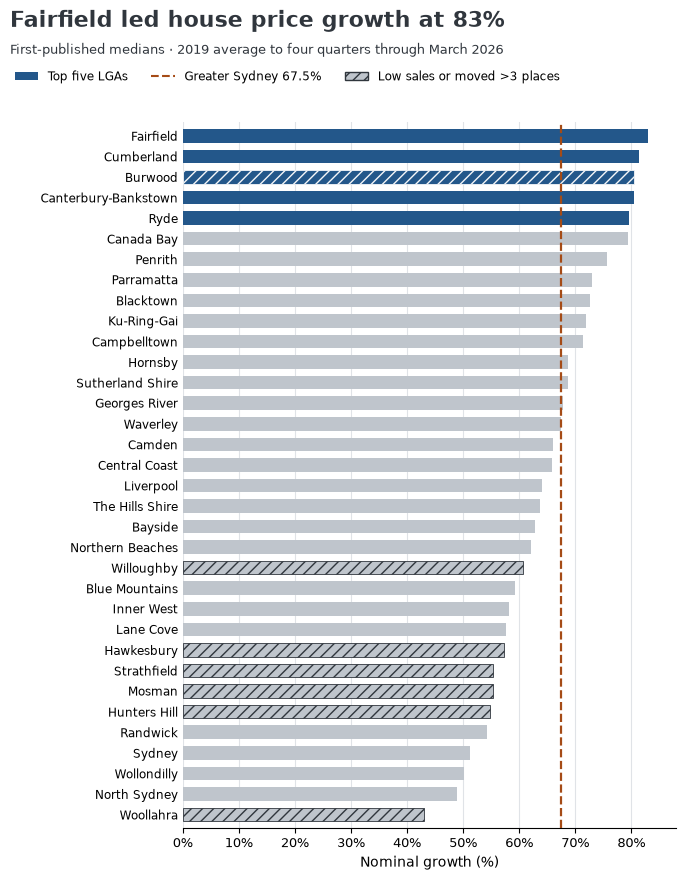

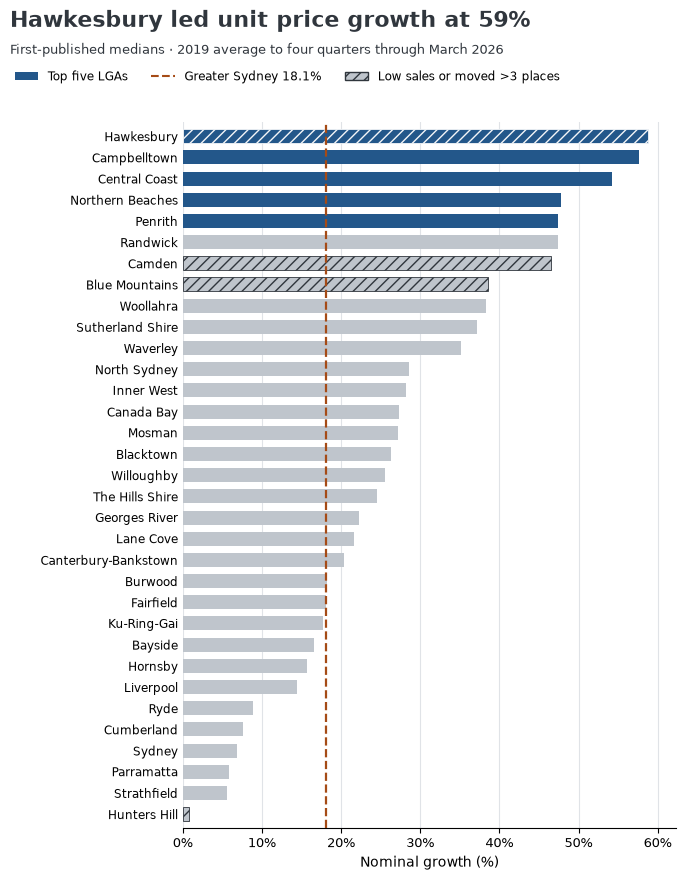

In [6]:
figure_dir = repo_root / "docs/figures"
figure_dir.mkdir(parents=True, exist_ok=True)
blue = "#23578A"
rust = "#A54B16"
light_grey = "#BFC5CC"
ink = "#30363D"
grid_grey = "#E0E3E7"

def save_chart(fig, filename):
    fig.savefig(figure_dir / filename, dpi=150, metadata={"Software": None}, facecolor="white")
    plt.show()
    plt.close(fig)

def plot_growth_bars(dwelling):
    series = ranked.loc[ranked["dwelling_type"].eq(dwelling)]
    leader = series.iloc[0]
    benchmark = benchmark_values.loc[("Greater Sydney", dwelling), "growth_pct"]
    colors = [blue if rank <= 5 else light_grey for rank in series["growth_rank"]]

    fig, ax = plt.subplots(figsize=(7.2, 9.15))
    fig.subplots_adjust(left=0.28, right=0.965, top=0.852, bottom=0.081)
    fig.text(0.04, 0.975, f"{leader['lga']} led {dwelling} price growth at {leader['growth_pct']:.0%}",
             fontsize=16, fontweight="bold", color=ink, va="top")
    fig.text(0.04, 0.939, f"First-published medians · 2019 average to four quarters through {end_label}",
             fontsize=9.5, color=ink, va="top")
    bars = ax.barh(series["lga"], series["growth_pct"], color=colors, height=0.66)
    for bar, color, has_caveat in zip(bars, colors, series["has_caveat"], strict=True):
        if has_caveat:
            bar.set_hatch("///")
            bar.set_edgecolor("#F4F6F8" if color == blue else ink)
            bar.set_linewidth(0.6)

    ax.axvline(benchmark, color=rust, linestyle="--", linewidth=1.6, zorder=3)
    ax.invert_yaxis()
    ax.set_ylim(len(series) - 0.35, -0.65)
    ax.set_xlim(min(0, series["growth_pct"].min()), 1.06 * max(benchmark, series["growth_pct"].max()))
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xlabel("Nominal growth (%)")
    ax.grid(axis="x", color=grid_grey)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", labelsize=8.3, length=0)
    ax.tick_params(axis="x", labelsize=9)
    legend = [
        Patch(facecolor=blue, label="Top five LGAs"),
        Line2D([0], [0], color=rust, linestyle="--", label=f"Greater Sydney {benchmark:.1%}"),
        Patch(facecolor=light_grey, edgecolor=ink, hatch="///", label="Low sales or moved >3 places"),
    ]
    fig.legend(handles=legend, loc="upper left", bbox_to_anchor=(0.04, 0.914), ncol=3,
               frameon=False, fontsize=8.5, borderaxespad=0)
    save_chart(fig, f"growth_by_lga_{dwelling}.png")

for dwelling in dwelling_types:
    plot_growth_bars(dwelling)

### Chart price indexes for Greater Sydney and each ring

Divide each quarter's first-published median by its own geography and dwelling type's 2019 average, then multiply by 100. Plot houses and units on the same vertical scale so the change in each ring is comparable.

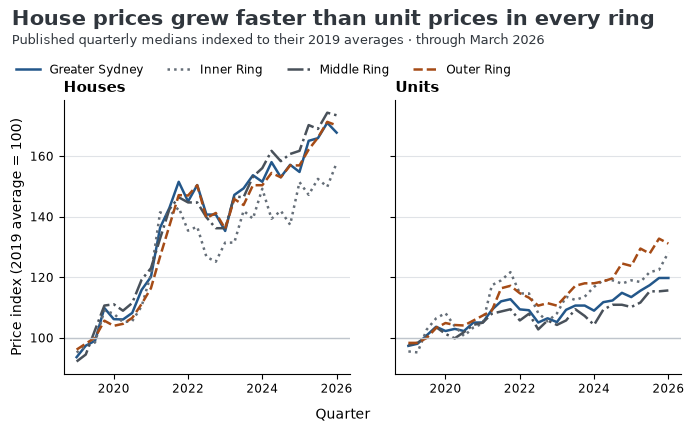

In [7]:
index_rows = sales.merge(
    benchmarks[["lga", "dwelling_type", "price_2019"]], on=["lga", "dwelling_type"], validate="many_to_one",
)
index_rows["price_index"] = 100 * index_rows["median_price"] / index_rows["price_2019"]
index_baseline = index_rows.loc[index_rows["quarter_date"].dt.year.eq(2019)]
index_averages = index_baseline.groupby(["lga", "dwelling_type"])["price_index"].mean()
assert index_averages.sub(100).abs().lt(1e-9).all()
assert len(index_rows) == 8 * len(dates)

line_styles = {
    "Greater Sydney": (blue, "-"), "Inner Ring": ("#656E78", ":"),
    "Middle Ring": ("#49515A", "-."), "Outer Ring": (rust, "--"),
}
fig, axes = plt.subplots(1, 2, figsize=(7.2, 4.45), sharey=True)
fig.subplots_adjust(left=0.112, right=0.97, bottom=0.15, top=0.765, wspace=0.16)
fig.text(0.04, 0.97, "House prices grew faster than unit prices in every ring",
         fontsize=15, fontweight="bold", va="top", color=ink)
fig.text(0.04, 0.916, f"Published quarterly medians indexed to their 2019 averages · through {end_label}",
         fontsize=9.3, va="top", color=ink)

for ax, dwelling in zip(axes, dwelling_types, strict=True):
    data = index_rows.loc[index_rows["dwelling_type"].eq(dwelling)]
    for name, (color, linestyle) in line_styles.items():
        line = data.loc[data["lga"].eq(name)].sort_values("quarter_date")
        ax.plot(line["quarter_date"], line["price_index"], color=color, linestyle=linestyle,
                linewidth=1.8, label=name)
    ax.axhline(100, color=light_grey, linewidth=1)
    ax.set_title(dwelling.capitalize() + "s", fontsize=11, loc="left", fontweight="bold")
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.grid(axis="y", color=grid_grey)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=8.5)
axes[0].set_ylabel("Price index (2019 average = 100)")
fig.supxlabel("Quarter", y=0.042, fontsize=10)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper left", bbox_to_anchor=(0.04, 0.858),
           ncol=4, fontsize=8.5, frameon=False, borderaxespad=0)
save_chart(fig, "price_index_rings.png")

### Draft findings

Summarise the benchmark, the leading LGAs and the effect of inflation. Flag a low-sales result where it affects a headline.

In [8]:
house_leader = ranked.loc[ranked["dwelling_type"].eq("house")].iloc[0]
unit_leader = ranked.loc[ranked["dwelling_type"].eq("unit")].iloc[0]
sydney_house = benchmark_values.loc[("Greater Sydney", "house")]
sydney_unit = benchmark_values.loc[("Greater Sydney", "unit")]
unit_low_sales = int(unit_leader["low_sales_quarters"])
unit_context = f", with {unit_low_sales} low-sales quarters across the two windows" if unit_low_sales else ""
unit_real = sydney_unit["growth_pct_real"]
unit_direction = "rose" if unit_real >= 0 else "fell"
findings = (
    f"From the 2019 average to the four quarters through {end_label}, Greater Sydney's median house "
    f"price rose {sydney_house['growth_pct']:.1%} and its unit median rose {sydney_unit['growth_pct']:.1%}. "
    f"{house_leader['lga']} led houses at {house_leader['growth_pct']:.1%} nominal growth "
    f"and {house_leader['growth_pct_real']:.1%} after inflation. "
    f"{unit_leader['lga']} led units in the first-published series at {unit_leader['growth_pct']:.1%}"
    f"{unit_context}. "
    f"After inflation, Greater Sydney house prices rose {sydney_house['growth_pct_real']:.1%} "
    f"and unit prices {unit_direction} {abs(unit_real):.1%}."
)
display(Markdown(findings))

From the 2019 average to the four quarters through March 2026, Greater Sydney's median house price rose 67.5% and its unit median rose 18.1%. Fairfield led houses at 83.0% nominal growth and 47.4% after inflation. Hawkesbury led units in the first-published series at 58.8%, with 4 low-sales quarters across the two windows. After inflation, Greater Sydney house prices rose 34.9% and unit prices fell 4.8%.